In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA579148/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibraryLayout,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,SRR10336636,AMPLICON,494,22125459,PRJNA579148,SAMN13103980,Metagenome or environmental,12078858,SHANGHAI NINTH PEOPLE'S HOSPITAL,2018-10-10,⋯,PAIRED,PCR,METATRANSCRIPTOMIC,oral metagenome,ILLUMINA,2019-10-24T00:00:00Z,2019-10-24T04:39:00Z,1,P156,SRP226726
2,SRR10336637,AMPLICON,494,19979032,PRJNA579148,SAMN13103979,Metagenome or environmental,11048528,SHANGHAI NINTH PEOPLE'S HOSPITAL,2018-10-09,⋯,PAIRED,PCR,METATRANSCRIPTOMIC,oral metagenome,ILLUMINA,2019-10-24T00:00:00Z,2019-10-24T04:39:00Z,1,P154,SRP226726
3,SRR10336638,AMPLICON,493,18721779,PRJNA579148,SAMN13103978,Metagenome or environmental,10308392,SHANGHAI NINTH PEOPLE'S HOSPITAL,2018-10-08,⋯,PAIRED,PCR,METATRANSCRIPTOMIC,oral metagenome,ILLUMINA,2019-10-24T00:00:00Z,2019-10-24T04:39:00Z,1,P153,SRP226726
4,SRR10336639,AMPLICON,493,25502658,PRJNA579148,SAMN13103977,Metagenome or environmental,13877594,SHANGHAI NINTH PEOPLE'S HOSPITAL,2018-10-07,⋯,PAIRED,PCR,METATRANSCRIPTOMIC,oral metagenome,ILLUMINA,2019-10-24T00:00:00Z,2019-10-24T04:39:00Z,1,P152,SRP226726
5,SRR10336640,AMPLICON,494,21036832,PRJNA579148,SAMN13104028,Metagenome or environmental,11718961,SHANGHAI NINTH PEOPLE'S HOSPITAL,2018-11-27,⋯,PAIRED,PCR,METATRANSCRIPTOMIC,oral metagenome,ILLUMINA,2019-10-24T00:00:00Z,2019-10-24T04:39:00Z,1,N217,SRP226726
6,SRR10336641,AMPLICON,494,22472061,PRJNA579148,SAMN13104027,Metagenome or environmental,12349078,SHANGHAI NINTH PEOPLE'S HOSPITAL,2018-11-26,⋯,PAIRED,PCR,METATRANSCRIPTOMIC,oral metagenome,ILLUMINA,2019-10-24T00:00:00Z,2019-10-24T04:39:00Z,1,N216,SRP226726


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "HOST"                           "Instrument"                    
[21] "isolation_source"               "lat_lon"                       
[23] "Library.Name"                   "LibraryLayout"                 
[25] "LibrarySelection"               "LibrarySource"                 
[27] "Organism"                       "Platform"                      
[29] "ReleaseDate"                    "create_date"                   
[31] "version"                        "Sample.Name"                   
[33] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V4-V5',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'subgingival plaque',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = "Microbial and metabolomic analysis of gingival crevicular fluid in general chronic periodontitis patients: lessons for a predictive, preventive, and personalized medical approach",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 58
[1] 58


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA579148,SRR10336636,P156,NA,NA,NA,V4-V5,ILLUMINA,China,subgingival plaque,2019-10-24T00:00:00Z,NA,"Microbial and metabolomic analysis of gingival crevicular fluid in general chronic periodontitis patients: lessons for a predictive, preventive, and personalized medical approach",YES,NA,NO
2,PRJNA579148,SRR10336637,P154,NA,NA,NA,V4-V5,ILLUMINA,China,subgingival plaque,2019-10-24T00:00:00Z,NA,"Microbial and metabolomic analysis of gingival crevicular fluid in general chronic periodontitis patients: lessons for a predictive, preventive, and personalized medical approach",YES,NA,NO
3,PRJNA579148,SRR10336638,P153,NA,NA,NA,V4-V5,ILLUMINA,China,subgingival plaque,2019-10-24T00:00:00Z,NA,"Microbial and metabolomic analysis of gingival crevicular fluid in general chronic periodontitis patients: lessons for a predictive, preventive, and personalized medical approach",YES,NA,NO
4,PRJNA579148,SRR10336639,P152,NA,NA,NA,V4-V5,ILLUMINA,China,subgingival plaque,2019-10-24T00:00:00Z,NA,"Microbial and metabolomic analysis of gingival crevicular fluid in general chronic periodontitis patients: lessons for a predictive, preventive, and personalized medical approach",YES,NA,NO
5,PRJNA579148,SRR10336640,N217,NA,NA,NA,V4-V5,ILLUMINA,China,subgingival plaque,2019-10-24T00:00:00Z,NA,"Microbial and metabolomic analysis of gingival crevicular fluid in general chronic periodontitis patients: lessons for a predictive, preventive, and personalized medical approach",YES,NA,NO
6,PRJNA579148,SRR10336641,N216,NA,NA,NA,V4-V5,ILLUMINA,China,subgingival plaque,2019-10-24T00:00:00Z,NA,"Microbial and metabolomic analysis of gingival crevicular fluid in general chronic periodontitis patients: lessons for a predictive, preventive, and personalized medical approach",YES,NA,NO


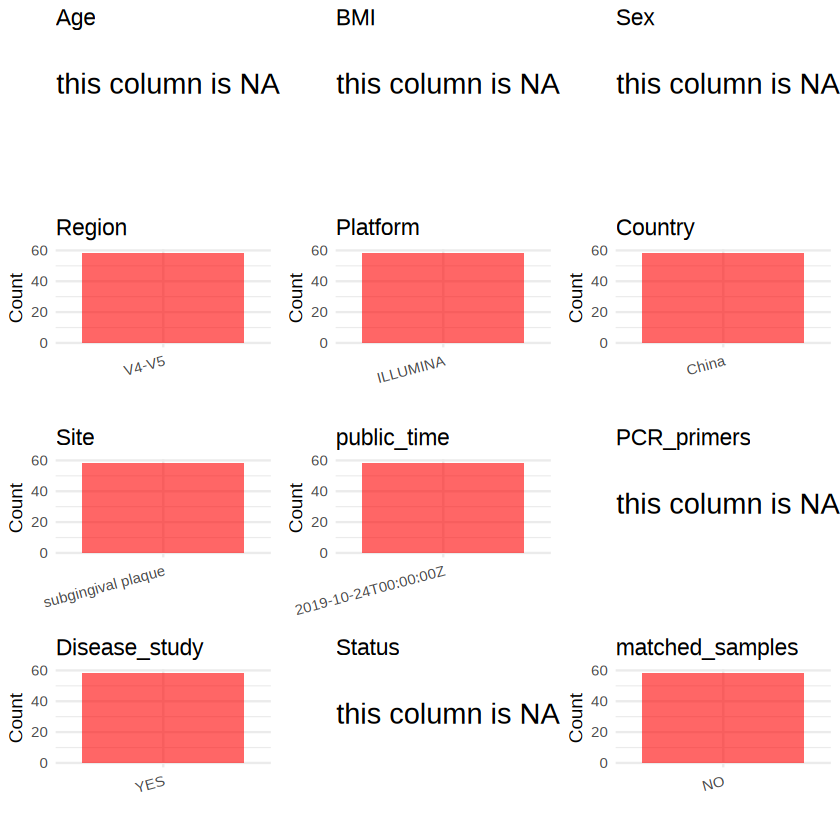

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA579148/metadata.csv", quote = T)